# ETL-10: Validación de salarios Sysarmy contra una fuente gremial (AGC)

**Materia:** Practicas Profesionalizantes 1

**Período de relevamiento del dataset: diciembre 2025 – febrero 2026** (dato informado por el equipo; el CSV no incluye una columna de fecha). Por eso la comparación se hace contra la **grilla salarial de la AGC vigente en esos meses** y no contra la más reciente.

**Objetivo:** contrastar los salarios autodeclarados del dataset de Sysarmy con una fuente gremial: la grilla salarial del **CCT 1696/23** de la Asociación Gremial de Computación (AGC).

**Fuentes (todas de la AGC, https://informaticos.ar):**
1. *Anexo: Estructura Remunerativa – Grillas Salariales Tercer Trimestre 2026* (Versión 07.2026), en https://informaticos.ar/convenios/. Trae los valores publicados por rol y seniority (junio a septiembre de 2026).
2. Nota *"La AGC acuerda un nuevo aumento salarial del 8% para el primer trimestre de 2026"* (21/01/2026): +3% enero, +6% febrero, +8% marzo, sobre los salarios de diciembre 2025.
3. Nota *"Segundo trimestre 2026: AGC logra 9,4% de incremento…"* (04/05/2026): +3,2% abril, +6,3% mayo, +9,4% junio, sobre los salarios de marzo 2026.

> **Punto metodológico clave:** el Anexo publicado contiene la grilla de **junio–septiembre 2026**, que es *posterior* al período del dataset. Los valores de **dic 2025, ene y feb 2026 se reconstruyen hacia atrás** aplicando los aumentos que la propia AGC documentó (fuentes 2 y 3). Son valores **estimados, no publicados**, y se marcan así en todo el notebook. Lo ideal es contrastarlos con el Anexo del 1T 2026 si el docente lo exige.

**Cómo se interpreta la comparación**
- Sysarmy es una encuesta *autodeclarada*; la AGC publica *pisos convencionales*. No se espera que coincidan: se evalúa si los salarios de Sysarmy son **consistentes** con esos pisos.
- La grilla es por **rol + seniority**. Comparación (A): *Developer* contra *Programador/a de software*. Comparación (B): todos los puestos con equivalente claro.
- El Anexo establece un **20% No Remunerativo** sobre el básico de cada mes (vigente también en el 1T y 2T 2026). No sabemos si `salario_bruto` lo incluye, así que se comparan **dos pisos**: básico y básico + 20%.
- Los pisos son **sin adicionales** (antigüedad 3% por año, título, idioma, líder de equipo).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Carga del dataset

In [2]:
RUTA_CSV = "../data/processed/sysarmy_limpio.csv"   # ruta relativa a analysis/ (ejecutar el notebook desde esa carpeta)
PERIODO_DATASET = ("Diciembre 2025", "Febrero 2026")   # período de relevamiento de la encuesta

# Si el archivo no existe, pandas lanza FileNotFoundError: es intencional.
# (La versión original reemplazaba el dataset por 4 filas de ejemplo sin avisar, lo que falseaba todo el análisis.)
df = pd.read_csv(RUTA_CSV)

columnas_necesarias = {"tipo_contrato", "dedicacion", "sueldo_dolarizado", "seniority", "salario_bruto", "puesto"}
faltantes = columnas_necesarias - set(df.columns)
assert not faltantes, f"Faltan columnas en el CSV: {faltantes}"
assert len(df) > 1000, f"El dataset tiene solo {len(df)} filas: ¿es el archivo completo?"

print(f"Dataset cargado desde {RUTA_CSV}: {df.shape[0]:,} registros y {df.shape[1]} columnas")
print(f"Período de relevamiento: {PERIODO_DATASET[0]} a {PERIODO_DATASET[1]}")
df.head()

Dataset cargado desde ../data/processed/sysarmy_limpio.csv: 4,939 registros y 15 columnas
Período de relevamiento: Diciembre 2025 a Febrero 2026


,id_respuesta,provincia_id,dedicacion,tipo_contrato,puesto,grupo_puesto,seniority,anios_experiencia,salario_bruto,pagos_en_dolares,sueldo_dolarizado,modalidad,uso_ia,genero,edad
0,1,50,Full-Time,Staff (planta permanente),Developer,Resto IT,Senior,15,3000000.0,Mi sueldo está dolarizado (pero cobro en moned...,1,Híbrido (presencial y remoto),3,Mujer Cis,45.0
1,2,82,Full-Time,Contractor,Developer,Resto IT,Senior,25,5000000.0,Cobro todo el salario en dólares,1,100% remoto,4,Mujer Cis,50.0
2,3,6,Full-Time,Tercerizado (trabajo a través de consultora o ...,Developer,Resto IT,Senior,7,4600000.0,Cobro parte del salario en dólares,1,100% remoto,5,Mujer Cis,36.0
3,4,2,Full-Time,Staff (planta permanente),Manager / Director,Resto IT,Senior,25,7800000.0,Cobro parte del salario en dólares,1,Híbrido (presencial y remoto),4,Hombre Cis,60.0
4,5,38,Full-Time,Contractor,SysAdmin / DevOps / SRE,Resto IT,Semi-Senior,3,3500000.0,Cobro todo el salario en dólares,1,100% remoto,4,Hombre Cis,29.0


## 2. Filtro: empleo registrado en pesos

Se aíslan los casos que **pueden estar bajo convenio** y cuyo sueldo está en pesos:

| Criterio | Qué se conserva | Por qué |
|---|---|---|
| `tipo_contrato` | Staff (planta permanente) y Tercerizado | Son relaciones de dependencia. Se excluyen Contractor, Freelance y cooperativas (no hay convenio aplicable). |
| `sueldo_dolarizado` | 0 | Un sueldo dolarizado no es comparable con un piso en pesos. |
| `dedicacion` | Full-Time | Los pisos convencionales son para jornada completa. |

In [3]:
CONTRATOS_VALIDOS = [
    "Staff (planta permanente)",
    "Tercerizado (trabajo a través de consultora o agencia)",
]

mascara = (
    df["tipo_contrato"].isin(CONTRATOS_VALIDOS)
    & (df["sueldo_dolarizado"] == 0)
    & (df["dedicacion"] == "Full-Time")
)
df_filtrado = df[mascara].copy()

print(f"Registros iniciales:               {len(df):,}")
print(f"Registros tras el filtro (pesos):  {len(df_filtrado):,}  ({len(df_filtrado)/len(df):.1%})")
print()
print("Registros por seniority tras el filtro:")
print(df_filtrado["seniority"].value_counts())

Registros iniciales:               4,939
Registros tras el filtro (pesos):  2,980  (60.3%)

Registros por seniority tras el filtro:
seniority
Senior         1705
Semi-Senior     945
Junior          330
Name: count, dtype: int64


## 3. Estadísticos salariales de Sysarmy por seniority (todos los puestos)

Se usa la **mediana** porque los salarios tienen cola larga hacia arriba y la media queda distorsionada por los valores altos. Los montos son **nominales de dic 2025 – feb 2026**.

In [4]:
NIVELES = ["Junior", "Semi-Senior", "Senior"]

resumen = (
    df_filtrado.groupby("seniority")["salario_bruto"]
    .agg(n="count",
         p25=lambda s: s.quantile(0.25),
         mediana="median",
         p75=lambda s: s.quantile(0.75))
    .reindex(NIVELES)
)
resumen.index.name = "Seniority"
resumen.style.format("{:,.0f}")

,n,p25,mediana,p75
Seniority,,,,
Junior,330,"1,332,283","1,789,027","2,478,000"
Semi-Senior,945,"2,000,000","2,600,000","3,500,000"
Senior,"1,705","2,708,000","3,800,000","5,031,375"


## 4. Fuente de comparación: grilla del CCT 1696/23 (AGC)

### 4.1 Valores publicados: Anexo 3T 2026 (junio a septiembre de 2026)

Básico remunerativo mensual (ARS), transcripto del Anexo. Varios roles comparten exactamente los mismos montos, por eso se definen tres bloques de valores.

In [5]:
NIVELES = ["Junior", "Semi-Senior", "Senior"]
MESES_ANEXO = ["Junio 2026", "Julio 2026", "Agosto 2026", "Septiembre 2026"]
INCREMENTO_SOBRE_JUNIO = {"Junio 2026": 0.0, "Julio 2026": 0.022, "Agosto 2026": 0.044, "Septiembre 2026": 0.067}
ADICIONAL_NO_REMUNERATIVO = 0.20   # 20% sobre el básico de cada mes (Anexo 3T 2026; también vigente en 1T y 2T 2026)

def _grilla(*por_mes):
    """por_mes: una tupla (Junior, Semi-Senior, Senior) por cada mes de MESES_ANEXO."""
    return {mes: dict(zip(NIVELES, vals)) for mes, vals in zip(MESES_ANEXO, por_mes)}

# Bloque A: Programador/a, Seguridad, DevOps/SysAdmin, Redes, Analista de Datos, DBA
_A = _grilla((1634047, 1879155, 2161028), (1669996, 1920496, 2208570),
             (1705945, 1961837, 2256113), (1743529, 2005058, 2305817))
# Bloque B: Calidad (QA), Analista Funcional, Diseñador UX/UI
_B = _grilla((1497877, 1722558, 1980942), (1530830, 1760455, 2024523),
             (1563783, 1798351, 2068104), (1598235, 1837970, 2113665))
# Bloque C: Soporte Técnico / Mesa de Ayuda
_C = _grilla((1361706, 1565962, 1800856), (1391664, 1600413, 1840475),
             (1421621, 1634864, 1880094), (1452941, 1670882, 1921514))

GRILLA_ANEXO_3T = {
    "Programador/a de software":                _A,
    "Analista de Seguridad Informática":        _A,
    "DevOps / Administrador de Sistemas":       _A,
    "Administrador de Redes e Infraestructura": _A,
    "Analista de Datos":                        _A,
    "Administrador Base de Datos":              _A,
    "Analista de Calidad de Software":          _B,
    "Analista Funcional":                       _B,
    "Diseñador/a de UX / UI":                   _B,
    "Soporte Técnico / Mesa de Ayuda":          _C,
}

# ---- Verificación de la transcripción contra las reglas del propio Anexo ----
errores = []
for rol, grilla in GRILLA_ANEXO_3T.items():
    for nivel in NIVELES:
        base = grilla["Junio 2026"][nivel]
        for mes in MESES_ANEXO[1:]:
            esperado = base * (1 + INCREMENTO_SOBRE_JUNIO[mes])
            if abs(grilla[mes][nivel] - esperado) / esperado > 0.0005:
                errores.append((rol, nivel, mes, grilla[mes][nivel], round(esperado)))
assert not errores, f"Posibles errores de transcripción: {errores}"
for rol, grilla in GRILLA_ANEXO_3T.items():
    for mes in MESES_ANEXO:
        g = grilla[mes]
        assert g["Junior"] < g["Semi-Senior"] < g["Senior"], f"Orden incorrecto en {rol} / {mes}"
assert GRILLA_ANEXO_3T["Programador/a de software"]["Septiembre 2026"]["Junior"] == 1743529

print(f"Verificación OK: {len(GRILLA_ANEXO_3T)} roles × 3 niveles × 4 meses coherentes con la regla +2,2% / +4,4% / +6,7%.")

Verificación OK: 10 roles × 3 niveles × 4 meses coherentes con la regla +2,2% / +4,4% / +6,7%.


**✔ Verificación contra el PDF oficial de la AGC**

Archivo contrastado: *AGC – Anexo CCT Empresas Informáticas – Tercer Trimestre 2026* (PDF, "Versión 07.2026").

- **Valor testigo:** Programador/a de software, nivel Junior, septiembre 2026 = **$1.743.529**. Figura en el PDF en la tabla *Salario Mínimo de Convenio* (p. 7) y en la *Grilla Salarial Remunerativa* (p. 8); coincide con lo cargado arriba (la celda anterior lo comprueba con un `assert`).
- **Verificación completa:** además se comparó automáticamente contra el texto del PDF cada una de las **120 cifras** transcriptas (10 roles × 3 niveles × 4 meses) y **coinciden las 120**.
- Esto valida solo los valores *publicados* (jun–sep 2026). Los valores de dic 2025 – mar 2026 son **reconstruidos** (sección 4.2) y no figuran en ese PDF.

### 4.2 Reconstrucción de la grilla del período del dataset (dic 2025 – mar 2026)

El Anexo publicado parte de **junio 2026**. Para llegar a los meses del dataset se deshacen los aumentos que la AGC informó:

| Tramo | Aumento documentado | Base de cálculo |
|---|---|---|
| 2T 2026 | +3,2% abril · +6,3% mayo · **+9,4% junio** | salarios de **marzo 2026** |
| 1T 2026 | +3% enero · +6% febrero · **+8% marzo** | salarios de **diciembre 2025** |

Por lo tanto: `marzo = junio / 1,094` y `diciembre = marzo / 1,08`; luego `enero = dic × 1,03` y `febrero = dic × 1,06`.

⚠️ **Son valores estimados.** Los porcentajes publicados están redondeados a una décima y asumimos que la estructura relativa de la grilla (roles y niveles) no cambió entre diciembre 2025 y junio 2026. El error esperado por redondeo es de pocos miles de pesos, pero conviene contrastarlos con el Anexo del 1T 2026.

In [6]:
AUMENTO_2T_JUNIO_SOBRE_MARZO = 0.094   # AGC, nota 04/05/2026
AUMENTO_1T = {"Enero 2026": 0.03, "Febrero 2026": 0.06, "Marzo 2026": 0.08}   # AGC, nota 21/01/2026, sobre dic 2025

MESES_RECONSTRUIDOS = ["Diciembre 2025", "Enero 2026", "Febrero 2026", "Marzo 2026"]

def _reconstruir(valor_junio):
    marzo = valor_junio / (1 + AUMENTO_2T_JUNIO_SOBRE_MARZO)
    dic = marzo / (1 + AUMENTO_1T["Marzo 2026"])
    return {
        "Diciembre 2025": round(dic),
        "Enero 2026":     round(dic * (1 + AUMENTO_1T["Enero 2026"])),
        "Febrero 2026":   round(dic * (1 + AUMENTO_1T["Febrero 2026"])),
        "Marzo 2026":     round(marzo),
    }

GRILLA_AGC = {}
for rol, meses in GRILLA_ANEXO_3T.items():
    GRILLA_AGC[rol] = {mes: dict(vals) for mes, vals in meses.items()}      # publicados
    for nivel in NIVELES:
        for mes, valor in _reconstruir(meses["Junio 2026"][nivel]).items():  # reconstruidos
            GRILLA_AGC[rol].setdefault(mes, {})[nivel] = valor

ORIGEN = {m: "publicado (Anexo 3T 2026)" for m in MESES_ANEXO}
ORIGEN.update({m: "reconstruido (estimado)" for m in MESES_RECONSTRUIDOS})

# Controles de coherencia de la reconstrucción
for rol, g in GRILLA_AGC.items():
    for nivel in NIVELES:
        assert g["Diciembre 2025"][nivel] < g["Enero 2026"][nivel] < g["Febrero 2026"][nivel] < g["Marzo 2026"][nivel] < g["Junio 2026"][nivel]
        # Ida y vuelta: marzo × 1,094 debe volver a junio (tolerancia de redondeo)
        assert abs(g["Marzo 2026"][nivel] * (1 + AUMENTO_2T_JUNIO_SOBRE_MARZO) - g["Junio 2026"][nivel]) <= 2

ejemplo = pd.DataFrame({m: GRILLA_AGC["Programador/a de software"][m] for m in
                        ["Diciembre 2025", "Enero 2026", "Febrero 2026", "Marzo 2026", "Junio 2026"]}).T
ejemplo["origen"] = [ORIGEN[m] for m in ejemplo.index]
print("Programador/a de software: básico remunerativo mensual (ARS)")
ejemplo.style.format({n: "{:,.0f}" for n in NIVELES})

Programador/a de software: básico remunerativo mensual (ARS)


,Junior,Semi-Senior,Senior,origen
Diciembre 2025,"1,383,004","1,590,456","1,829,024",reconstruido (estimado)
Enero 2026,"1,424,494","1,638,169","1,883,894",reconstruido (estimado)
Febrero 2026,"1,465,984","1,685,883","1,938,765",reconstruido (estimado)
Marzo 2026,"1,493,644","1,717,692","1,975,346",reconstruido (estimado)
Junio 2026,"1,634,047","1,879,155","2,161,028",publicado (Anexo 3T 2026)


In [7]:
# Chequeo de plausibilidad (orientativo, no es una comprobación exacta):
# La AGC publicó que en el 3T 2025 el mínimo de un QA Junior, con teletrabajo, sin antigüedad ni idioma, quedaba en
# "prácticamente un millón y medio" (https://informaticos.ar/aumento-del-6-para-los-salarios-informaticos-bajo-convenio-de-la-agc/).
# Estimación hacia atrás desde nuestra grilla: sept 2025 ≈ dic 2025 / 1,06 (el 4T 2025 fue de ≈6% según el OTI/AGC, a confirmar).
qa_jr_dic25 = GRILLA_AGC["Analista de Calidad de Software"]["Diciembre 2025"]["Junior"]
qa_jr_sep25_con_nr = qa_jr_dic25 / 1.06 * (1 + ADICIONAL_NO_REMUNERATIVO)
print(f"QA Junior, estimación sept 2025: básico + 20% ≈ ${qa_jr_sep25_con_nr:,.0f}")
print("Falta sumar el reintegro por teletrabajo (monto de sept 2025 no verificado). Un orden de magnitud cercano a $1,5 M "
      "es compatible con lo publicado por la AGC, pero conviene verificarlo contra el Anexo del 3T 2025.")

QA Junior, estimación sept 2025: básico + 20% ≈ $1,435,193
Falta sumar el reintegro por teletrabajo (monto de sept 2025 no verificado). Un orden de magnitud cercano a $1,5 M es compatible con lo publicado por la AGC, pero conviene verificarlo contra el Anexo del 3T 2025.


### 4.3 Parámetros de la comparación

- **`MES_REF = "Enero 2026"`**: el dataset cubre dic 2025 – feb 2026 y no sabemos en qué mes respondió cada persona. Se toma el **mes central** como referencia, y en la sección 9 se muestra cuánto cambia el resultado con diciembre y febrero.
- **Mapeo de puestos:** solo se incluyen los puestos de Sysarmy con un equivalente claro en el convenio. Los ambiguos (*Data Engineer*, *Architect*, *Technical Leader*, *Manager*, *Business Analyst*, etc.) **no se mapean** para no forzar una equivalencia; el diccionario es editable.

In [8]:
MESES_PERIODO = ["Diciembre 2025", "Enero 2026", "Febrero 2026"]   # meses de la grilla que coinciden con el relevamiento
MES_REF = "Enero 2026"

MAPEO_PUESTOS = {   # puesto en Sysarmy  ->  rol en la grilla AGC
    "Developer":                 "Programador/a de software",
    "QA / Tester":               "Analista de Calidad de Software",
    "SysAdmin / DevOps / SRE":   "DevOps / Administrador de Sistemas",
    "BI Analyst / Data Analyst": "Analista de Datos",
    "Infosec":                   "Analista de Seguridad Informática",
    "Functional Analyst":        "Analista Funcional",
    "HelpDesk":                  "Soporte Técnico / Mesa de Ayuda",
    "Technical Support":         "Soporte Técnico / Mesa de Ayuda",
    "DBA":                       "Administrador Base de Datos",
    "Networking":                "Administrador de Redes e Infraestructura",
    "UX/UI Designer":            "Diseñador/a de UX / UI",
}

assert MES_REF in MESES_PERIODO
assert set(MAPEO_PUESTOS.values()) <= set(GRILLA_AGC), "Hay roles mapeados que no están en la grilla"

def piso_remunerativo(rol, nivel, mes=MES_REF):
    return GRILLA_AGC[rol][mes][nivel]

def piso_con_nr(rol, nivel, mes=MES_REF):
    return piso_remunerativo(rol, nivel, mes) * (1 + ADICIONAL_NO_REMUNERATIVO)

print(f"Período del dataset: {PERIODO_DATASET[0]} – {PERIODO_DATASET[1]}")
print(f"Grilla de referencia: {MES_REF} ({ORIGEN[MES_REF]}) · Adicional no remunerativo: {ADICIONAL_NO_REMUNERATIVO:.0%}")

Período del dataset: Diciembre 2025 – Febrero 2026
Grilla de referencia: Enero 2026 (reconstruido (estimado)) · Adicional no remunerativo: 20%


## 5. Comparación A: Developer (Sysarmy) vs. Programador/a de software (AGC)

Es el cruce más directo y con más casos. Para cada seniority:
- **Brecha:** distancia de la mediana de Sysarmy respecto de cada piso.
- **% bajo el piso:** proporción de developers que declara menos que el piso. Es más robusta que comparar solo medianas.

In [9]:
ROL_A = "Programador/a de software"
dev = df_filtrado[df_filtrado["puesto"] == "Developer"]

comp_a = dev.groupby("seniority")["salario_bruto"].agg(n="count", Mediana_Sysarmy="median").reindex(NIVELES)
comp_a.index.name = "Seniority"
comp_a["Piso_basico"]    = [piso_remunerativo(ROL_A, n) for n in comp_a.index]
comp_a["Piso_basico+NR"] = [piso_con_nr(ROL_A, n) for n in comp_a.index]

comp_a["Brecha_vs_basico_%"]    = (comp_a["Mediana_Sysarmy"] / comp_a["Piso_basico"] - 1) * 100
comp_a["Brecha_vs_basico+NR_%"] = (comp_a["Mediana_Sysarmy"] / comp_a["Piso_basico+NR"] - 1) * 100

for col_piso, col_out in [("Piso_basico", "%_bajo_basico"), ("Piso_basico+NR", "%_bajo_basico+NR")]:
    comp_a[col_out] = [
        (dev.loc[dev["seniority"] == n, "salario_bruto"] < comp_a.loc[n, col_piso]).mean() * 100
        for n in comp_a.index
    ]

print(f"Developers en pesos, full-time, bajo convenio potencial: n = {len(dev):,}")
print(f"Grilla AGC: {MES_REF} ({ORIGEN[MES_REF]})  ·  dataset: {PERIODO_DATASET[0]} – {PERIODO_DATASET[1]}")
comp_a.style.format({
    "n": "{:,.0f}", "Mediana_Sysarmy": "{:,.0f}", "Piso_basico": "{:,.0f}", "Piso_basico+NR": "{:,.0f}",
    "Brecha_vs_basico_%": "{:+.1f}%", "Brecha_vs_basico+NR_%": "{:+.1f}%",
    "%_bajo_basico": "{:.1f}%", "%_bajo_basico+NR": "{:.1f}%",
})

Developers en pesos, full-time, bajo convenio potencial: n = 909
Grilla AGC: Enero 2026 (reconstruido (estimado))  ·  dataset: Diciembre 2025 – Febrero 2026


,n,Mediana_Sysarmy,Piso_basico,Piso_basico+NR,Brecha_vs_basico_%,Brecha_vs_basico+NR_%,%_bajo_basico,%_bajo_basico+NR
Seniority,,,,,,,,
Junior,116,"1,700,000","1,424,494","1,709,393",+19.3%,-0.5%,37.9%,53.4%
Semi-Senior,374,"2,696,330","1,638,169","1,965,803",+64.6%,+37.2%,12.6%,20.9%
Senior,419,"3,635,546","1,883,894","2,260,673",+93.0%,+60.8%,7.2%,12.6%


## 6. Comparación B: todos los puestos con equivalente en el convenio

Cada respuesta de Sysarmy se compara con **el piso de su propio rol y seniority**. La métrica es el cociente `salario / piso` (1,00 = justo en el piso).

In [10]:
df_map = df_filtrado[df_filtrado["puesto"].isin(MAPEO_PUESTOS)].copy()
df_map["rol_agc"] = df_map["puesto"].map(MAPEO_PUESTOS)
df_map["piso_basico"]    = [piso_remunerativo(r, s) for r, s in zip(df_map["rol_agc"], df_map["seniority"])]
df_map["piso_basico_nr"] = [piso_con_nr(r, s)       for r, s in zip(df_map["rol_agc"], df_map["seniority"])]
df_map["ratio_basico"]    = df_map["salario_bruto"] / df_map["piso_basico"]
df_map["ratio_basico_nr"] = df_map["salario_bruto"] / df_map["piso_basico_nr"]

print(f"Registros con puesto mapeado: {len(df_map):,} de {len(df_filtrado):,} ({len(df_map)/len(df_filtrado):.1%}). "
      f"El resto no se compara por no tener un rol equivalente claro.\n")

def resumir(g):
    return pd.Series({
        "n": len(g),
        "Mediana_salario": g["salario_bruto"].median(),
        "Mediana_ratio_vs_basico": g["ratio_basico"].median(),
        "Mediana_ratio_vs_basico+NR": g["ratio_basico_nr"].median(),
        "%_bajo_basico": (g["ratio_basico"] < 1).mean() * 100,
        "%_bajo_basico+NR": (g["ratio_basico_nr"] < 1).mean() * 100,
    })

fmt_b = {"n": "{:,.0f}", "Mediana_salario": "{:,.0f}", "Mediana_ratio_vs_basico": "{:.2f}",
         "Mediana_ratio_vs_basico+NR": "{:.2f}", "%_bajo_basico": "{:.1f}%", "%_bajo_basico+NR": "{:.1f}%"}

print("Por seniority:")
display(df_map.groupby("seniority").apply(resumir, include_groups=False).reindex(NIVELES).style.format(fmt_b))
print("Por puesto de Sysarmy (todos los seniority juntos):")
display(df_map.groupby("puesto").apply(resumir, include_groups=False).sort_values("n", ascending=False).style.format(fmt_b))

Registros con puesto mapeado: 1,856 de 2,980 (62.3%). El resto no se compara por no tener un rol equivalente claro.

Por seniority:


,n,Mediana_salario,Mediana_ratio_vs_basico,Mediana_ratio_vs_basico+NR,%_bajo_basico,%_bajo_basico+NR
seniority,,,,,,
Junior,232,"1,718,099",1.23,1.03,28.9%,47.8%
Semi-Senior,683,"2,500,000",1.53,1.28,15.2%,25.5%
Senior,941,"3,400,000",1.80,1.50,9.6%,17.2%


Por puesto de Sysarmy (todos los seniority juntos):


,n,Mediana_salario,Mediana_ratio_vs_basico,Mediana_ratio_vs_basico+NR,%_bajo_basico,%_bajo_basico+NR
puesto,,,,,,
Developer,909,"2,950,640",1.70,1.42,13.3%,21.2%
SysAdmin / DevOps / SRE,359,"3,000,000",1.68,1.40,11.7%,22.6%
QA / Tester,142,"2,146,500",1.34,1.12,19.0%,38.7%
BI Analyst / Data Analyst,124,"2,600,000",1.58,1.32,13.7%,25.8%
Infosec,81,"3,358,093",1.96,1.64,12.3%,18.5%
HelpDesk,65,"1,712,000",1.21,1.01,30.8%,49.2%
UX/UI Designer,58,"2,652,500",1.70,1.41,8.6%,10.3%
Networking,54,"2,820,500",1.62,1.35,14.8%,24.1%
Functional Analyst,23,"2,236,000",1.33,1.11,17.4%,30.4%


## 7. Evidencia visual (comparación A)

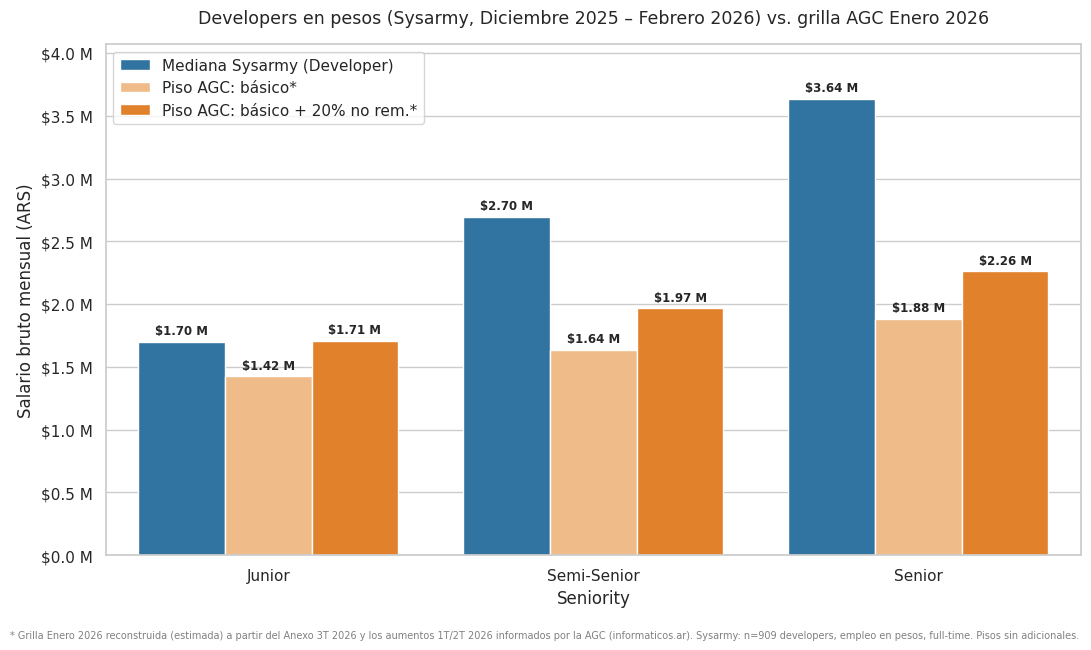

In [11]:
df_plot = (
    comp_a[["Mediana_Sysarmy", "Piso_basico", "Piso_basico+NR"]]
    .reset_index()
    .melt(id_vars="Seniority", var_name="Serie", value_name="Salario")
)
df_plot["Serie"] = df_plot["Serie"].map({
    "Mediana_Sysarmy": "Mediana Sysarmy (Developer)",
    "Piso_basico": "Piso AGC: básico*",
    "Piso_basico+NR": "Piso AGC: básico + 20% no rem.*",
})

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.barplot(data=df_plot, x="Seniority", y="Salario", hue="Serie", order=NIVELES,
            palette=["#1f77b4", "#ffbb78", "#ff7f0e"], ax=ax)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x/1e6:.1f} M"))
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"${v/1e6:.2f} M" for v in cont.datavalues], padding=3, fontsize=8.5, fontweight="bold")

ax.set_title(f"Developers en pesos (Sysarmy, {PERIODO_DATASET[0]} – {PERIODO_DATASET[1]}) vs. grilla AGC {MES_REF}",
             fontsize=12.5, pad=15)
ax.set_xlabel("Seniority")
ax.set_ylabel("Salario bruto mensual (ARS)")
ax.set_ylim(0, df_plot["Salario"].max() * 1.12)
ax.legend(title="", loc="upper left")
fig.text(0.01, 0.005,
         f"* Grilla {MES_REF} reconstruida (estimada) a partir del Anexo 3T 2026 y los aumentos 1T/2T 2026 informados por la AGC (informaticos.ar). "
         f"Sysarmy: n={len(dev):,} developers, empleo en pesos, full-time. Pisos sin adicionales.",
         fontsize=7, color="gray")

plt.tight_layout(rect=(0, 0.025, 1, 1))
plt.savefig("evidencia_comparativa_salarios.png", dpi=300)
plt.show()

## 8. Sensibilidad: ¿cambia el resultado según el mes de la grilla?

Como no se sabe en qué mes respondió cada persona, se repite la comparación A con **diciembre, enero y febrero**. Como contraste, se agrega **septiembre 2026** (grilla vigente al día de hoy): esa fila **no corresponde al período del dataset** y se incluye solo para mostrar qué pasaría si se comparara con la grilla más reciente sin ajustar por fecha.

In [12]:
filas = []
meses_sens = MESES_PERIODO + ["Septiembre 2026"]
for mes in meses_sens:
    fila = {("Mes de la grilla", ""): mes + (" (fuera del período; solo contraste)" if mes not in MESES_PERIODO else "")}
    for nivel in NIVELES:
        s = dev.loc[dev["seniority"] == nivel, "salario_bruto"]
        fila[("% bajo piso básico", nivel)]      = (s < piso_remunerativo(ROL_A, nivel, mes)).mean() * 100
        fila[("% bajo piso básico + 20%", nivel)] = (s < piso_con_nr(ROL_A, nivel, mes)).mean() * 100
    filas.append(fila)

sens = pd.DataFrame(filas)
sens.columns = pd.MultiIndex.from_tuples(sens.columns)
sens = sens.set_index(("Mes de la grilla", ""))
sens.index.name = "Mes de la grilla"
sens.style.format("{:.1f}%")

,% bajo piso básico,% bajo piso básico + 20%,% bajo piso básico,% bajo piso básico + 20%,% bajo piso básico,% bajo piso básico + 20%
,Junior,Junior,Semi-Senior,Semi-Senior,Senior,Senior
Mes de la grilla,,,,,,
Diciembre 2025,33.6%,47.4%,11.8%,20.3%,6.9%,11.0%
Enero 2026,37.9%,53.4%,12.6%,20.9%,7.2%,12.6%
Febrero 2026,38.8%,56.9%,13.1%,23.8%,7.2%,14.1%
Septiembre 2026 (fuera del período; solo contraste),56.0%,75.9%,23.5%,38.2%,13.8%,24.3%


## 9. Registro de la fuente y de las diferencias encontradas

In [13]:
print("REGISTRO DE VALIDACIÓN (generado automáticamente a partir de los resultados)")
print("=" * 78)
print("Fuente elegida : Asociación Gremial de Computación (AGC)")
print("Documentos     : Anexo Grillas Salariales 3T 2026 (Versión 07.2026), CCT 1696/23 · notas AGC 1T 2026 (21/01/2026) y 2T 2026 (04/05/2026)")
print("URL            : https://informaticos.ar/convenios/   (consultado: 2026-10-17)")
print(f"Período dataset: {PERIODO_DATASET[0]} – {PERIODO_DATASET[1]} (informado por el equipo)")
print(f"Grilla usada   : {MES_REF}, rol Programador/a de software, sin adicionales — {ORIGEN[MES_REF].upper()}")
print(f"Muestra        : {len(dev):,} developers (de {len(df):,} respuestas); empleo en pesos, full-time, staff/tercerizado")
print()
print("Comparación A (Developer vs. Programador/a):")
for n in NIVELES:
    r = comp_a.loc[n]
    print(f"  {n:<12} n={int(r['n']):>4} | mediana Sysarmy ${r['Mediana_Sysarmy']:>12,.0f} | "
          f"piso básico ${r['Piso_basico']:>10,.0f} ({r['Brecha_vs_basico_%']:+.1f}%) | "
          f"piso +NR ${r['Piso_basico+NR']:>10,.0f} ({r['Brecha_vs_basico+NR_%']:+.1f}%) | "
          f"bajo piso básico: {r['%_bajo_basico']:.1f}% · bajo piso +NR: {r['%_bajo_basico+NR']:.1f}%")
print()
print("Comparación B (todos los puestos mapeados):")
print(f"  {len(df_map):,} registros · mediana del cociente salario/piso básico = {df_map['ratio_basico'].median():.2f} · "
      f"salario/piso básico+NR = {df_map['ratio_basico_nr'].median():.2f}")
print(f"  % bajo piso básico: {(df_map['ratio_basico'] < 1).mean()*100:.1f}% · % bajo piso básico+NR: {(df_map['ratio_basico_nr'] < 1).mean()*100:.1f}%")
print()
print("Evidencia a adjuntar: evidencia_comparativa_salarios.png + PDF del Anexo Salarial 3T 2026 + capturas de las notas AGC del 1T y 2T 2026.")

REGISTRO DE VALIDACIÓN (generado automáticamente a partir de los resultados)
Fuente elegida : Asociación Gremial de Computación (AGC)
Documentos     : Anexo Grillas Salariales 3T 2026 (Versión 07.2026), CCT 1696/23 · notas AGC 1T 2026 (21/01/2026) y 2T 2026 (04/05/2026)
URL            : https://informaticos.ar/convenios/   (consultado: 2026-10-17)
Período dataset: Diciembre 2025 – Febrero 2026 (informado por el equipo)
Grilla usada   : Enero 2026, rol Programador/a de software, sin adicionales — RECONSTRUIDO (ESTIMADO)
Muestra        : 909 developers (de 4,939 respuestas); empleo en pesos, full-time, staff/tercerizado

Comparación A (Developer vs. Programador/a):
  Junior       n= 116 | mediana Sysarmy $   1,700,000 | piso básico $ 1,424,494 (+19.3%) | piso +NR $ 1,709,393 (-0.5%) | bajo piso básico: 37.9% · bajo piso +NR: 53.4%
  Semi-Senior  n= 374 | mediana Sysarmy $   2,696,330 | piso básico $ 1,638,169 (+64.6%) | piso +NR $ 1,965,803 (+37.2%) | bajo piso básico: 12.6% · bajo piso 

## 10. Conclusión y limitaciones

*Los números de esta sección corresponden a la ejecución con la **grilla de enero 2026 reconstruida** (mes central del período dic 2025 – feb 2026). Si se cambia `MES_REF` o los datos, hay que revisarlos.*

### Conclusiones

1. **Los salarios de Sysarmy son consistentes con la grilla de la AGC vigente en el período del dataset.** En *Developer*, la mediana de Semi-Senior ($2,70 M) y de Senior ($3,64 M) supera el piso de Programador/a incluso sumando el 20% no remunerativo (+37% y +61% respectivamente; +65% y +93% sobre el básico). Solo el 21% de los Semi-Senior y el 13% de los Senior declara menos que el piso con adicional.
2. **En el nivel Junior la mediana queda prácticamente sobre el piso.** La mediana de Sysarmy ($1,70 M) está +19% sobre el básico y −0,5% respecto del básico + 20% ($1,71 M). El 38% de los juniors declara menos que el básico y el 53% menos que el básico + 20%. Es una zona de superposición: no se puede afirmar que Sysarmy "supere" el piso en este nivel, y el resultado depende de si `salario_bruto` incluye el no remunerativo (dato que se desconoce).
3. **La distancia al piso crece con el seniority** (+19% / +65% / +93% sobre el básico). Es lo esperable si el convenio fija mínimos y el mercado paga más en los niveles altos, aunque este análisis no permite probar la causa.
4. **La comparación ampliada (B) apunta en la misma dirección.** Con 1.856 registros de 11 puestos mapeados, la mediana del cociente salario/piso es 1,61 (1,35 con el no remunerativo) y el 14% (24% con no remunerativo) queda bajo el piso. Los puestos más cercanos al piso son *HelpDesk* y *Technical Support* (cociente de 1,01 y 0,93 con no remunerativo); el más alejado es *Infosec* (1,96 sobre el básico), seguido de *Developer*, *UX/UI* y *DBA* (≈1,70). Algunos puestos tienen pocos casos (DBA n=21, Functional Analyst n=23), por lo que sus resultados son más inestables.
5. **El período del dataset importa.** Si se comparara con la grilla de septiembre 2026 (que no corresponde a estas encuestas), el porcentaje de juniors bajo el piso con no remunerativo subiría de 53% a 76%, y el de semi-senior de 21% a 38%. Comparar sin ajustar por fecha **exagera** la distancia desfavorable. Dentro del período, el resultado Junior es sensible al mes elegido (47% a 57% bajo el piso con no remunerativo entre diciembre y febrero; sección 8).

### Limitaciones

- **Grilla reconstruida, no publicada.** Los valores de dic 2025 – mar 2026 se calcularon deshaciendo los aumentos informados por la AGC (+8% del 1T 2026 y +9,4% del 2T 2026) a partir del Anexo del 3T 2026. Los porcentajes están redondeados y se asume que la estructura de roles y niveles no cambió. **Se recomienda validarlos contra el Anexo oficial del 1T 2026.** El chequeo de plausibilidad del 3T 2025 es solo orientativo.
- **Período del dataset informado, no verificable en el CSV.** El archivo no tiene columna de fecha; el rango dic 2025 – feb 2026 es el que informó el equipo. Además no se sabe en qué mes respondió cada persona (por eso se usa enero como referencia y se muestra la sensibilidad).
- **Autodeclaración vs. piso:** Sysarmy refleja lo que cada persona informó; la AGC publica mínimos convencionales, no salarios promedio. Que Sysarmy esté por encima del piso es lo esperable y no indica un error en ninguna fuente.
- **Criterio sobre el 20% no remunerativo:** se desconoce si `salario_bruto` lo incluye; por eso se presentan los dos pisos. La lectura prudente es el rango entre ambos.
- **Salarios muy bajos:** el dataset tiene valores mínimos de $200.000 mensuales (posibles errores de carga, jornada reducida o ingresos parciales), que inflan el "% bajo el piso".
- **Pisos sin adicionales:** antigüedad (3% por año), título, idioma y liderazgo elevan lo que cobra una persona bajo convenio, por lo que el piso real individual puede ser mayor.
- **Mapeo de roles:** es una decisión de criterio; los puestos ambiguos se excluyeron de la comparación B.
- **Cobertura:** el convenio aplica a empresas cuya actividad principal es informática; parte de los respondentes puede trabajar en empresas no encuadradas en él.
- **Valores nominales:** los salarios y la grilla están en pesos corrientes de cada mes; no se ajustó por inflación.
